In [ ]:
!pip install torch torchvision torchaudio
!pip install scikit-learn seaborn tqdm matplotlib


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation


/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
SOURCE = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged"
TARGET = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/dummy"
TEST   = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"

In [ ]:
!python dann_mobilenetv2.py \
  --source-dir "$SOURCE" \
  --target-dir "$TARGET" \
  --test-dir "$TEST" \
  --out-dir /content/drive/MyDrive/Colab\ Results/DANN_MOBILENETV2 \
  --epochs 30 \
  --iters-per-epoch 300 \
  --batch-size 16 \
  --lambda-val 1.0 \
  --lr 1e-4 \
  --device cuda


Loading datasets...
Building model...
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100% 13.6M/13.6M [00:00<00:00, 174MB/s]
Training DANN...
DANN Train Ep 1/30: 100% 300/300 [11:01<00:00,  2.21s/it, cls=0.778, dom=0.757, loss=1.53]
DANN Train Ep 2/30: 100% 300/300 [10:31<00:00,  2.10s/it, cls=0.743, dom=0.651, loss=1.39]
DANN Train Ep 3/30: 100% 300/300 [10:23<00:00,  2.08s/it, cls=1.64, dom=0.73, loss=2.37]
DANN Train Ep 4/30: 100% 300/300 [10:21<00:00,  2.07s/it, cls=1.23, dom=0.661, loss=1.89]
DANN Train Ep 5/30: 100% 300/300 [10:17<00:00,  2.06s/it, cls=0.772, dom=0.7, loss=1.47]
DANN Train Ep 6/30: 100% 300/300 [02:54<00:00,  1.72it/s, cls=0.957, dom=0.703, loss=1.66]
DANN Train Ep 7/30: 100% 300/300 [00:42<00:00,  7.10it/s, cls=0.759, dom=0.68, loss=1.44]
DANN Train Ep 8/30: 100% 300/300 [00:42<00:00,  7.09it/s, cls=0.395, dom=0.646, loss=1.04]
DANN Train Ep 9/30: 100% 300/300 [00:42<00

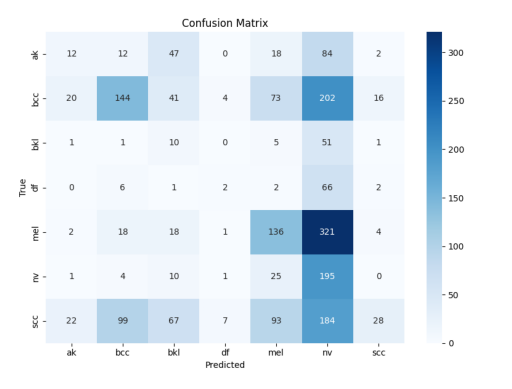

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/content/drive/MyDrive/Colab Results/DANN_MOBILENETV2/confusion_matrix.png')
plt.imshow(img)
plt.axis('off')
plt.show()


In [ ]:
import pandas as pd
report = pd.read_csv('/content/drive/MyDrive/Colab Results/DANN_MOBILENETV2/classification_report.csv', index_col=0)
report


,precision,recall,f1-score,support
ak,0.206897,0.068571,0.103004,175.000000
bcc,0.507042,0.288000,0.367347,500.000000
bkl,0.051546,0.144928,0.076046,69.000000
df,0.133333,0.025316,0.042553,79.000000
mel,0.386364,0.272000,0.319249,500.000000
nv,0.176791,0.826271,0.291262,236.000000
scc,0.528302,0.056000,0.101266,500.000000
accuracy,0.255949,0.255949,0.255949,0.255949
macro avg,0.284325,0.240155,0.185818,2059.000000
weighted avg,0.389934,0.255949,0.237641,2059.000000


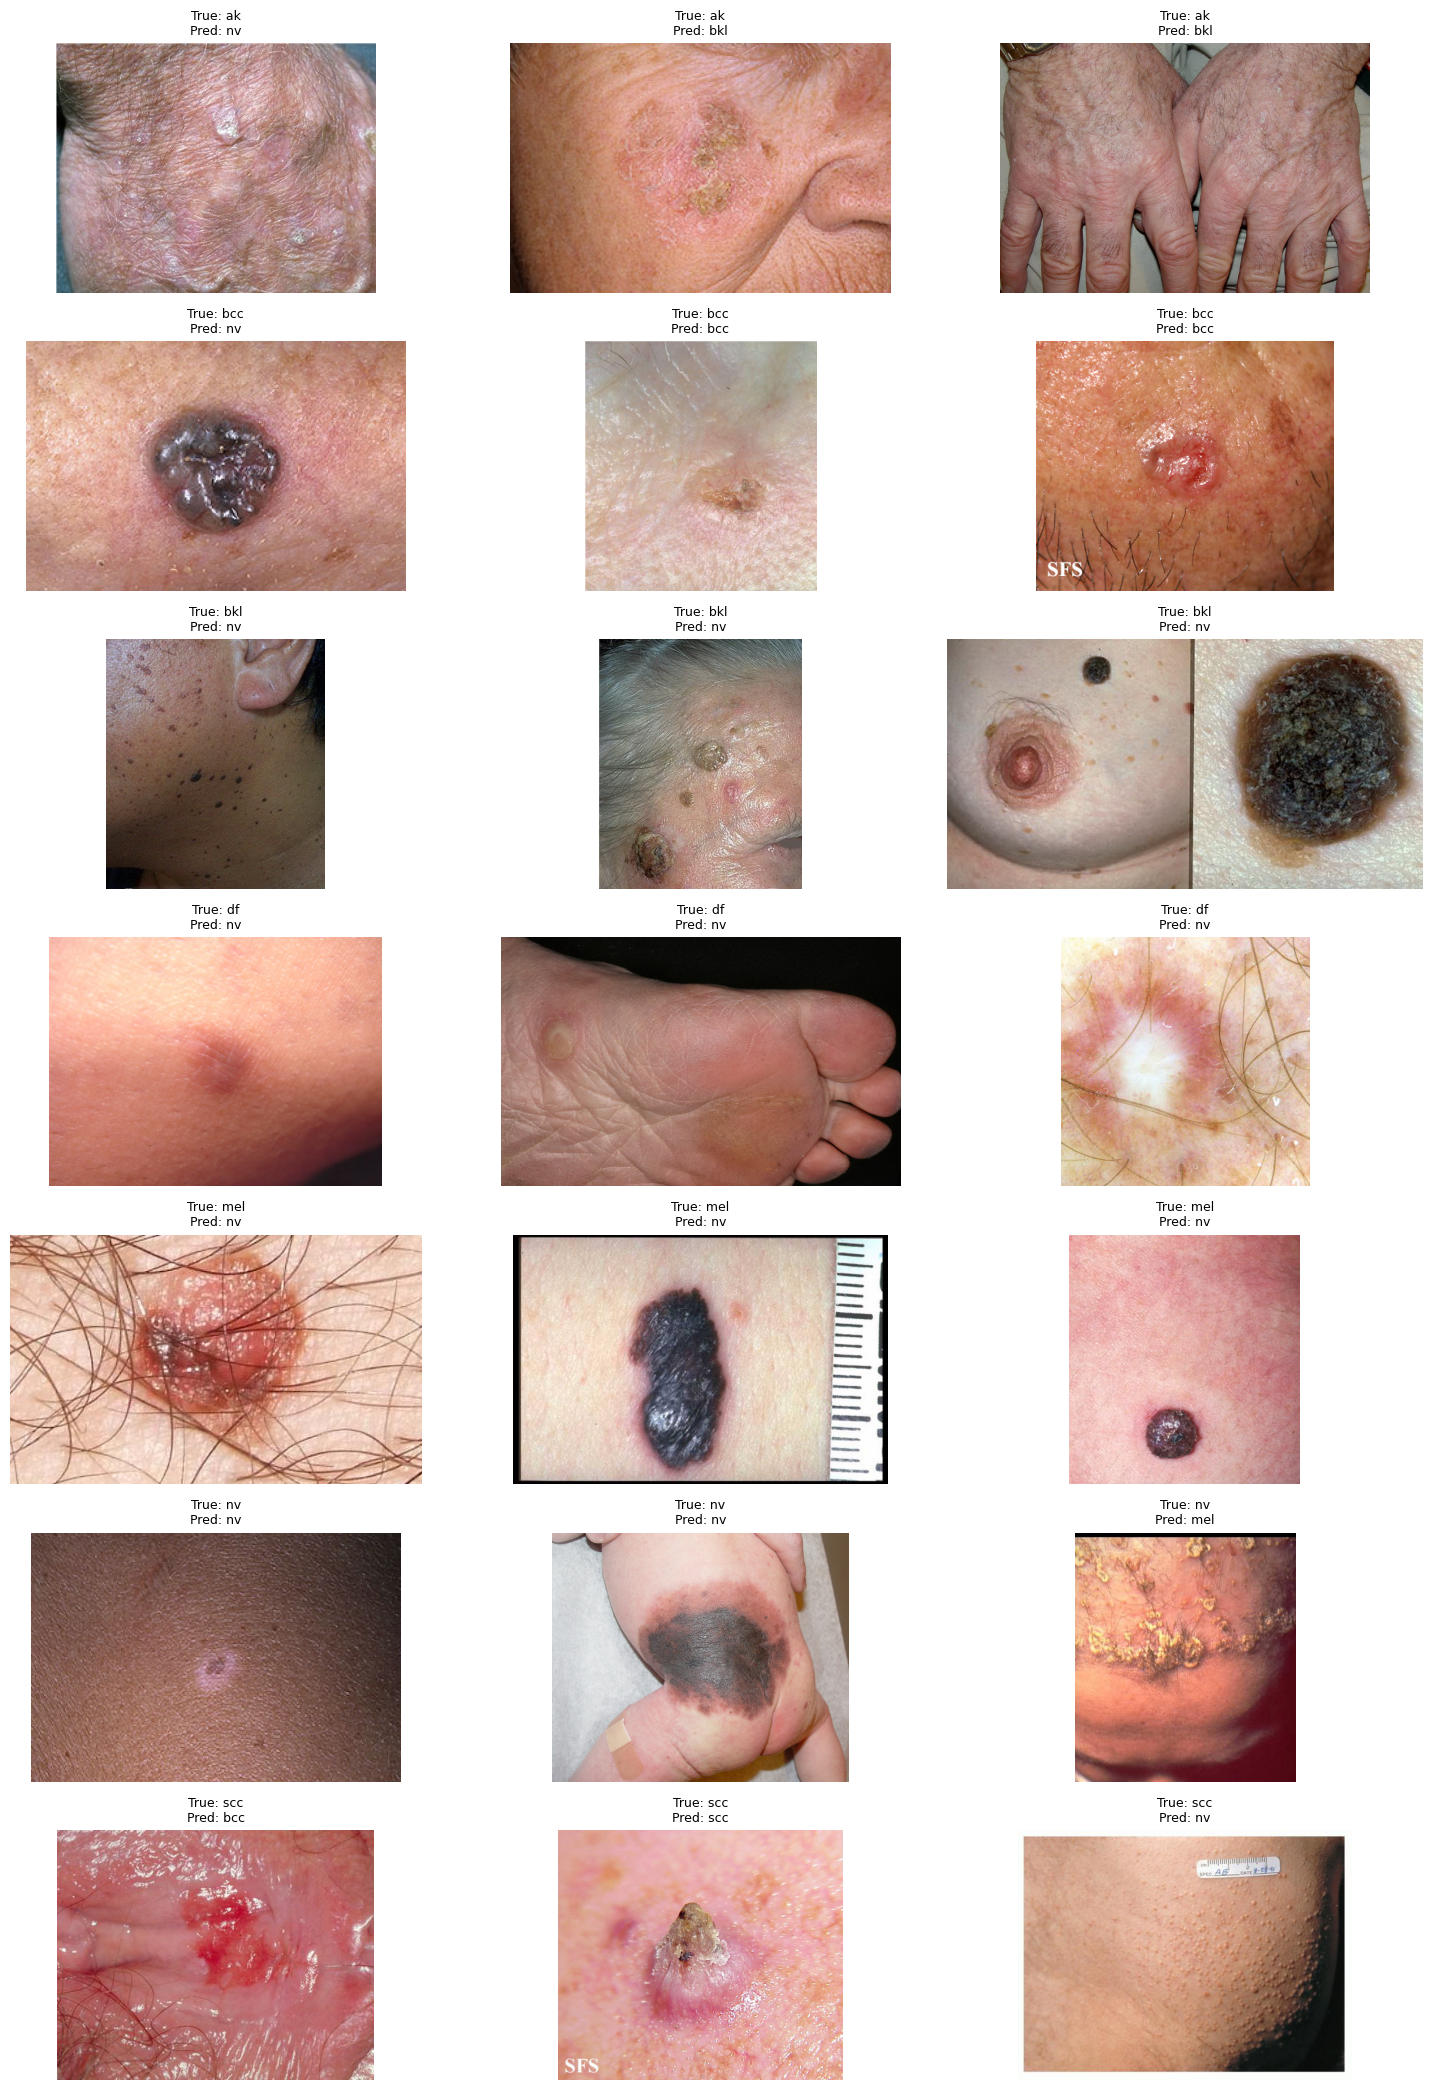

In [ ]:
import os
import torch
import random
import matplotlib.pyplot as plt
import numpy as np
from torchvision import transforms
from PIL import Image

# ---- Paths ----
TEST_DIR = TEST  # reuse your test path from earlier
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- Load model ----
from dann_mobilenetv2 import get_mobilenetv2_encoder, ClassifierHead

encoder, feat_dim = get_mobilenetv2_encoder(pretrained=False)
classifier = ClassifierHead(feat_dim, num_classes=7)

checkpoint = torch.load('/content/drive/MyDrive/Colab Results/DANN_MOBILENETV2/full_model.pth', map_location=device)
encoder.load_state_dict(checkpoint['encoder'])
classifier.load_state_dict(checkpoint['classifier'])
encoder.to(device).eval()
classifier.to(device).eval()

# ---- Prepare transform ----
tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# ---- Get class folders ----
class_dirs = [os.path.join(TEST_DIR, c) for c in os.listdir(TEST_DIR) if os.path.isdir(os.path.join(TEST_DIR, c))]
class_dirs.sort()
classes = [os.path.basename(c) for c in class_dirs]

# ---- Predict samples ----
num_samples = 3  # how many per class
plt.figure(figsize=(15, len(classes)*3))

for i, (cls, cls_dir) in enumerate(zip(classes, class_dirs)):
    images = random.sample([os.path.join(cls_dir, x) for x in os.listdir(cls_dir) if x.endswith(('.jpg','.png','.jpeg'))], num_samples)

    for j, img_path in enumerate(images):
        img = Image.open(img_path).convert("RGB")
        inp = tfm(img).unsqueeze(0).to(device)
        with torch.no_grad():
            pred = classifier(encoder(inp)).argmax(1).item()

        plt.subplot(len(classes), num_samples, i*num_samples + j + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"True: {cls}\nPred: {classes[pred]}", fontsize=9)

plt.tight_layout()
plt.show()
